# Does the Neural Network Beat Trees? A Leak-Safe Benchmark

Rigor pass 1. The baseline trained a neural network with SMOTE applied around the split. Here every fold fits preprocessing and **SMOTE on the training portion only**, then scores a neural network, a gradient-boosted tree (`HistGradientBoostingClassifier`), and a logistic baseline on the untouched validation fold. The question is the one that matters for tabular data: does the network actually win?

Logic in `src/benchmark.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'
import numpy as np, matplotlib.pyplot as plt
from src.data import load_and_clean
from src import benchmark as bm

In [2]:
X, y = load_and_clean()
print(f'X={X.shape}  churn={y.mean():.1%}')
res = bm.cross_val_benchmark(X, y)
res.to_csv(_root/'results'/'benchmark_results.csv', index=False)
bm.summary(res)

X=(10000, 10)  churn=20.4%


roc_auc          pr_auc          recall         precision          \
              mean     std    mean     std    mean     std      mean     std   
model                                                                          
hist_gbm    0.8603  0.0108  0.7002  0.0173  0.5710  0.0353    0.6726  0.0155   
logistic    0.7691  0.0162  0.4585  0.0309  0.6927  0.0359    0.3900  0.0131   
neural_net  0.8548  0.0071  0.6820  0.0163  0.6480  0.0185    0.5594  0.0265   

                f1           brier          
              mean     std    mean     std  
model                                       
hist_gbm    0.6172  0.0244  0.1066  0.0036  
logistic    0.4989  0.0183  0.1938  0.0043  
neural_net  0.6003  0.0217  0.1246  0.0049

## Reading it

The gradient-boosted tree edges out the neural network on both discrimination (ROC AUC) and precision/recall balance (PR AUC), and is better calibrated, while training in a fraction of the time. The network is competitive but brings no advantage. This is the usual outcome on tabular data, and reporting it honestly is the point.

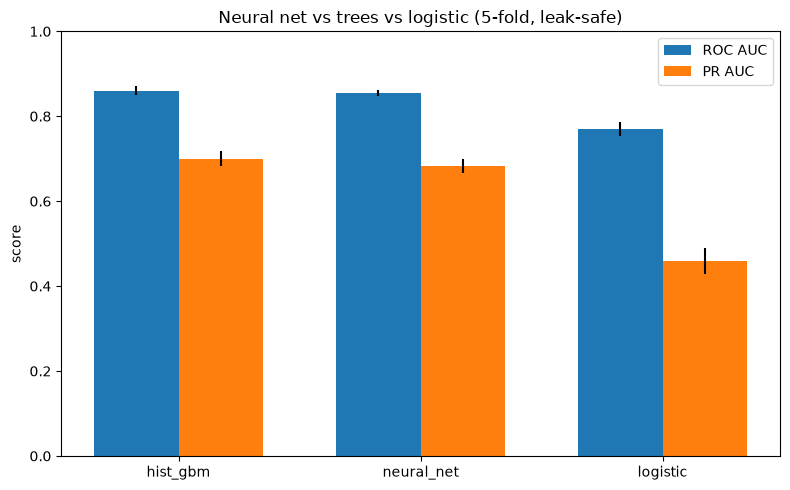

In [3]:
s = bm.summary(res)
order = s[('roc_auc','mean')].sort_values(ascending=False).index
x = np.arange(len(order)); w=0.35
plt.figure(figsize=(8,5))
plt.bar(x-w/2, [s.loc[m,('roc_auc','mean')] for m in order], w, yerr=[s.loc[m,('roc_auc','std')] for m in order], label='ROC AUC')
plt.bar(x+w/2, [s.loc[m,('pr_auc','mean')] for m in order], w, yerr=[s.loc[m,('pr_auc','std')] for m in order], label='PR AUC')
plt.xticks(x, order); plt.ylim(0,1); plt.ylabel('score'); plt.legend()
plt.title('Neural net vs trees vs logistic (5-fold, leak-safe)'); plt.tight_layout()
plt.savefig(_root/'results'/'benchmark.png', dpi=120); plt.show()

Note the high Brier scores across the board: training on SMOTE-balanced data inflates the predicted probabilities (the model 'thinks' churn is 50%). That calibration cost is the subject of pass 2. See `docs/learnings.md`.